# 决策树课堂笔记：从基尼不纯度到树的分裂

本 Notebook 按 2026-11 版《机器学习课堂笔记》第 5 章整理，覆盖：

- 决策树的基本概念：根节点、内部节点、分支、叶子节点
- 基尼不纯度及其公式
- 加权基尼与基尼增益
- 第二层分裂：跳过无区分能力的特征
- 决策树的停止条件
- 数值特征与阈值：候选分割点、最优阈值
- sklearn 决策树的训练、节点读取和可视化

依赖：

```bash
pip install numpy pandas scikit-learn matplotlib
```

In [2]:
# %matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
np.set_printoptions(precision=4, suppress=True)

## 5.1 决策树的概念

决策树就是一套分层判断的“问答流程图”：

- **根节点**：最开头第一个判断问题；
- **内部节点**：中间的每一个提问、判断条件；
- **分支**：每个问题的不同答案；
- **叶子节点**：最后的结论，不再继续分叉。

决策树的目标：用尽量少的问题，把数据尽量分开，让同一个叶子里的类别尽量一致、纯净。

哪个特征放在前面，不是随便排的，而是算法根据“区分能力”算出来的：优先把最能区分数据的特征放在上层。

## 5.2 基尼不纯度

基尼不纯度衡量一堆样本有多“混杂”：

- 基尼值越大，数据越杂；
- 基尼值越小，数据越纯。

直观理解：闭上眼睛，有放回地连续抽两张卡片，**抽到不同类别的概率**就是基尼不纯度。

设正类占比为 $p$，负类占比为 $1-p$：

$$
\text{Gini}
=1-p^2-(1-p)^2
=2p(1-p)
$$

多分类时：

$$
\text{Gini}=1-\sum_{k=1}^{K}p_k^2
$$

其中 $p_k$ 是第 $k$ 类样本在集合中的占比。

基尼只是衡量混乱程度，和预测准不准不是一回事。决策树分裂时追求的是：**分裂后基尼下降**。

In [3]:
def gini(y):
    """二分类基尼不纯度：Gini = 1 - p^2 - (1-p)^2。"""
    y = np.array(y)
    if len(y) == 0:
        return 0.0
    p = y.mean()
    return 1 - p**2 - (1 - p)**2


for name, labels in [
    ("全部违约", [1, 1, 1, 1]),
    ("全部正常", [0, 0, 0, 0]),
    ("一半一半", [1, 1, 0, 0]),
    ("1 个违约 3 个正常", [1, 0, 0, 0]),
]:
    print(f"{name} 基尼={gini(labels):.3f}")

全部违约 基尼=0.000
全部正常 基尼=0.000
一半一半 基尼=0.500
1 个违约 3 个正常 基尼=0.375


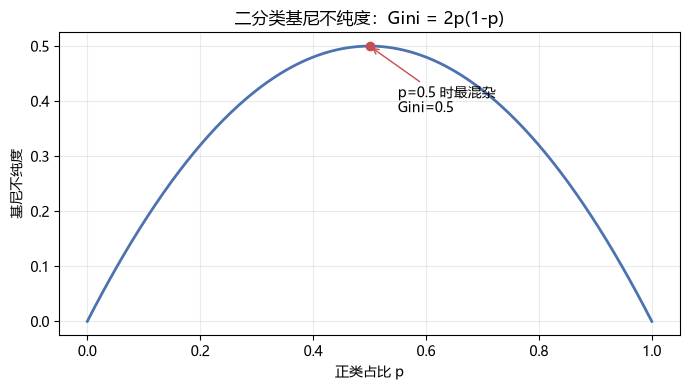

In [4]:
p_grid = np.linspace(0, 1, 300)
gini_grid = 2 * p_grid * (1 - p_grid)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p_grid, gini_grid, color="#4C72B0", linewidth=2)
ax.scatter([0.5], [0.5], color="#C44E52", zorder=3)
ax.annotate("p=0.5 时最混杂\nGini=0.5", xy=(0.5, 0.5), xytext=(0.55, 0.38),
            arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.set_xlabel("正类占比 p")
ax.set_ylabel("基尼不纯度")
ax.set_title("二分类基尼不纯度：Gini = 2p(1-p)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("images/notes13_fig_gini.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.3 加权基尼

决策树一次分裂会把节点切成左右两组。两组的样本数一般不同，不能直接对两个基尼求简单平均，而要按人数加权：

$$
\text{Gini}_{\text{split}}
=\frac{n_L}{n}\text{Gini}_L
+\frac{n_R}{n}\text{Gini}_R
$$

其中：

- $n$：分裂前节点样本数；
- $n_L,n_R$：左右子节点样本数；
- $\text{Gini}_L,\text{Gini}_R$：左右子节点自己的基尼。

基尼增益：

$$
\Delta\text{Gini}
=\text{Gini}_{\text{parent}}
-\text{Gini}_{\text{split}}
$$

**加权基尼越小，这次分裂越好。** 决策树会在所有候选分裂中，选择加权基尼最小的那个。

例子：左边 7 人、基尼 0.4；右边 3 人、基尼 0.1：

$$
\text{Gini}_{\text{split}}
=0.4\times\frac{7}{10}+0.1\times\frac{3}{10}
=0.31
$$

In [5]:
case1 = pd.DataFrame({
    "有房产":   ["无", "有", "无", "无", "无", "无", "无", "有", "无", "有"],
    "工作稳定": ["稳定", "稳定", "稳定", "稳定", "不稳定", "不稳定", "不稳定", "不稳定", "稳定", "稳定"],
    "信用记录": ["较差", "较差", "良好", "较差", "较差", "良好", "较差", "良好", "良好", "良好"],
    "是否违约": [1, 0, 0, 1, 1, 0, 1, 0, 0, 0],
}, index=range(1, 11))

X1 = pd.DataFrame({
    "有房产": (case1["有房产"] == "有").astype(int),
    "工作稳定": (case1["工作稳定"] == "稳定").astype(int),
    "信用良好": (case1["信用记录"] == "良好").astype(int),
})
y1 = case1["是否违约"].to_numpy()

display(case1)
display(X1)

,有房产,工作稳定,信用记录,是否违约
1,无,稳定,较差,1
2,有,稳定,较差,0
3,无,稳定,良好,0
4,无,稳定,较差,1
5,无,不稳定,较差,1
6,无,不稳定,良好,0
7,无,不稳定,较差,1
8,有,不稳定,良好,0
9,无,稳定,良好,0
10,有,稳定,良好,0


,有房产,工作稳定,信用良好
1,0,1,0
2,1,1,0
3,0,1,1
4,0,1,0
5,0,0,0
6,0,0,1
7,0,0,0
8,1,0,1
9,0,1,1
10,1,1,1


In [6]:
def weighted_gini(y, mask):
    """mask=True 去右边，False 去左边；返回左右基尼和加权基尼。"""
    left, right = y[~mask], y[mask]
    gl, gr = gini(left), gini(right)
    wg = (len(left) * gl + len(right) * gr) / len(y)
    return gl, gr, wg


for col in X1.columns:
    mask = X1[col].to_numpy() == 1
    gl, gr, wg = weighted_gini(y1, mask)
    print(
        f"{col:<5} 左 {(~mask).sum()} 人（违约 {y1[~mask].sum()}）基尼 {gl:.4f}  "
        f"右 {mask.sum()} 人（违约 {y1[mask].sum()}）基尼 {gr:.4f}  "
        f"加权基尼 {wg:.4f}"
    )

有房产   左 7 人（违约 4）基尼 0.4898  右 3 人（违约 0）基尼 0.0000  加权基尼 0.3429
工作稳定  左 4 人（违约 2）基尼 0.5000  右 6 人（违约 2）基尼 0.4444  加权基尼 0.4667
信用良好  左 5 人（违约 4）基尼 0.3200  右 5 人（违约 0）基尼 0.0000  加权基尼 0.1600


以“信用记录”为例：

- 信用较差 5 人，其中 4 人违约，$p=4/5=0.8$，基尼 $=1-0.8^2-0.2^2=0.32$；
- 信用良好 5 人全部正常，基尼 $=0$；
- 加权基尼 $=0.32\times\frac{5}{10}+0\times\frac{5}{10}=0.16$。

三个特征的加权基尼分别是：

- 有房产：0.3429
- 工作稳定：0.4667
- 信用良好：0.1600

信用记录最小，所以根节点先问“信用良好吗？”。

## 5.4 第二层：跳过无区分能力的特征

根节点按“信用良好”切开后：

- 信用良好的一组基尼为 0，已经纯净，直接成为叶子节点；
- 信用较差的一组还有 4 个违约、1 个正常，基尼 0.32，需要继续分裂。

在信用较差的 5 个人里，“信用良好”全部等于 0，所有人取值相同，这个特征无法再区分他们，必须跳过。

如果某个特征在当前节点所有样本上取值都相同，它没有区分能力，不参与加权基尼计算。

In [7]:
sub = X1["信用良好"].to_numpy() == 0
Xs, ys = X1[sub], y1[sub]

print("当前节点：", len(ys), "人，违约", ys.sum(), "人，基尼", round(gini(ys), 4))

for col in X1.columns:
    vals = Xs[col].to_numpy()
    if len(set(vals)) == 1:
        print(f"{col:<5} 所有人都一样，跳过")
        continue
    gl, gr, wg = weighted_gini(ys, vals == 1)
    print(f"{col:<5} 加权基尼 {wg:.4f}")

当前节点： 5 人，违约 4 人，基尼 0.32
有房产   加权基尼 0.0000
工作稳定  加权基尼 0.2667
信用良好  所有人都一样，跳过


第二层结果：

- 有房产：加权基尼 0，切完两组都纯净，选它；
- 工作稳定：加权基尼 0.2667，也能分，但不如有房产；
- 信用良好：所有人取值相同，跳过。

分裂后继续对新子集重复：基尼为 0 就停止；还混杂就继续找最小加权基尼的特征。

## 5.5 决策树什么时候停止分裂

两个最基础的停止条件：

1. **节点已经纯净**：基尼 = 0，节点里所有标签相同；
2. **没有特征可以继续拆分**：剩下的特征在当前节点无法把样本分开。

sklearn 默认会一直分裂，直到所有叶子节点都纯净。这样长满的树很容易过拟合，后续需要用 `max_depth`、`min_samples_leaf` 等参数剪枝。

In [8]:
tree1 = DecisionTreeClassifier(random_state=0).fit(X1, y1)
t = tree1.tree_

for k in range(t.node_count):
    if t.children_left[k] == -1:
        kind = "叶子"
    else:
        kind = f"按 {X1.columns[t.feature[k]]} <= {t.threshold[k]:.3f} 划分"
    print(f"节点{k}: {t.n_node_samples[k]} 人，基尼 {t.impurity[k]:.4f}，{kind}")

节点0: 10 人，基尼 0.4800，按 信用良好 <= 0.500 划分
节点1: 5 人，基尼 0.3200，按 有房产 <= 0.500 划分
节点2: 4 人，基尼 0.0000，叶子
节点3: 1 人，基尼 0.0000，叶子
节点4: 5 人，基尼 0.0000，叶子


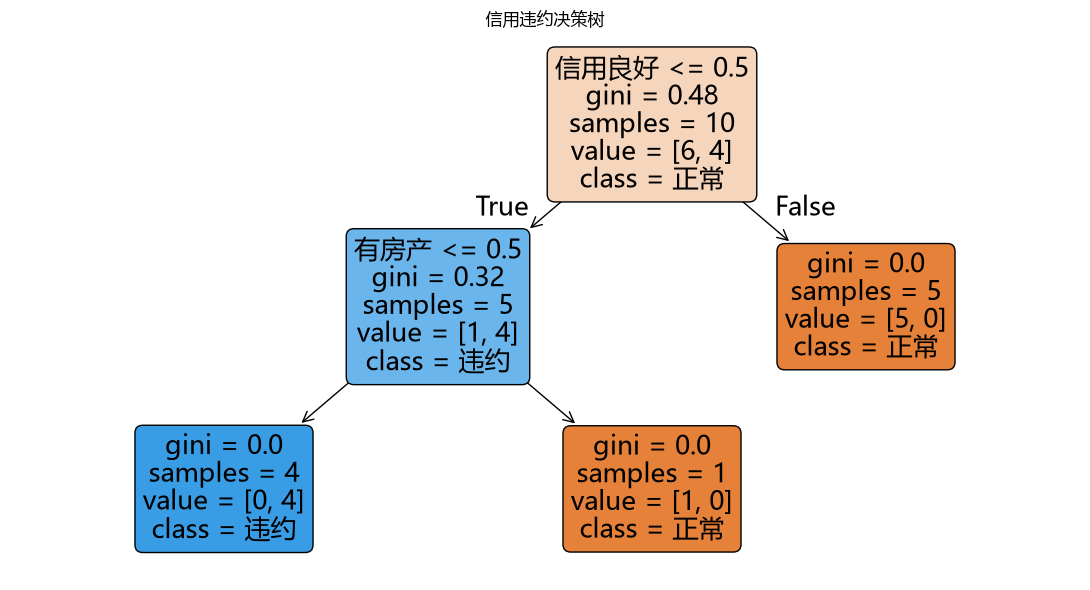

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_tree(
    tree1,
    feature_names=list(X1.columns),
    class_names=["正常", "违约"],
    filled=True,
    rounded=True,
    ax=ax,
)
ax.set_title("信用违约决策树")
fig.tight_layout()
fig.savefig("images/notes13_fig_tree_case.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.6 数值特征与阈值

前面的特征是 0/1 类别，问题很好提。月收入这种连续数值特征不能问“收入等于 3 吗”，因为取值太碎、泛化差。

决策树对数值特征统一问：

$$
x \le t \;?
$$

其中 $t$ 是分割阈值。回答只有“是/否”，刚好把节点切成左右两支。

### 5.6.1 怎么找阈值

1. 把该特征的取值从小到大排序；
2. 在相邻两个不同取值的中间生成候选阈值：

$$
t_i=\frac{x_i+x_{i+1}}{2}
$$

3. 对每个候选阈值计算分裂后的加权基尼；
4. 选择加权基尼最小（基尼增益最大）的阈值。

In [10]:
income = np.array([3, 5, 6, 8, 9, 11, 13, 14, 16, 19])
y2 = np.array([1, 1, 1, 0, 1, 0, 0, 0, 0, 0])

display(pd.DataFrame({"月收入": income, "是否违约": y2}, index=range(1, 11)).T)

xs = np.unique(income)
mids = (xs[:-1] + xs[1:]) / 2

for t_ in mids:
    gl, gr, wg = weighted_gini(y2, income > t_)
    print(f"月收入 <= {t_:>4}: 左基尼 {gl:.4f}  右基尼 {gr:.4f}  加权基尼 {wg:.4f}")

best = mids[np.argmin([weighted_gini(y2, income > t_)[2] for t_ in mids])]
print("最好的阈值:", best)

,1,2,3,4,5,6,7,8,9,10
月收入,3,5,6,8,9,11,13,14,16,19
是否违约,1,1,1,0,1,0,0,0,0,0


月收入 <=  4.0: 左基尼 0.0000  右基尼 0.4444  加权基尼 0.4000
月收入 <=  5.5: 左基尼 0.0000  右基尼 0.3750  加权基尼 0.3000
月收入 <=  7.0: 左基尼 0.0000  右基尼 0.2449  加权基尼 0.1714
月收入 <=  8.5: 左基尼 0.3750  右基尼 0.2778  加权基尼 0.3167
月收入 <= 10.0: 左基尼 0.3200  右基尼 0.0000  加权基尼 0.1600
月收入 <= 12.0: 左基尼 0.4444  右基尼 0.0000  加权基尼 0.2667
月收入 <= 13.5: 左基尼 0.4898  右基尼 0.0000  加权基尼 0.3429
月收入 <= 15.0: 左基尼 0.5000  右基尼 0.0000  加权基尼 0.4000
月收入 <= 17.5: 左基尼 0.4938  右基尼 0.0000  加权基尼 0.4444
最好的阈值: 10.0


在收入例子中，最优阈值是 **10.0**：

- 月收入 ≤ 10 的一侧：基尼约 0.32；
- 月收入 > 10 的一侧：基尼 0；
- 加权基尼约 0.16，是所有候选阈值中最小的。

In [11]:
X_income = income.reshape(-1, 1)
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=1,
    random_state=42,
).fit(X_income, y2)

tree = dt.tree_
best_th_sk = tree.threshold[0]
left_idx = tree.children_left[0]
right_idx = tree.children_right[0]
gl_sk = tree.impurity[left_idx]
gr_sk = tree.impurity[right_idx]
n_left = tree.n_node_samples[left_idx]
n_right = tree.n_node_samples[right_idx]
wg_sk = (n_left * gl_sk + n_right * gr_sk) / (n_left + n_right)

print(f"模型找到的最优分割阈值: {best_th_sk}")
print(f"左分支基尼 gl={gl_sk:.4f}，样本数={n_left}")
print(f"右分支基尼 gr={gr_sk:.4f}，样本数={n_right}")
print(f"对应加权基尼 wg={wg_sk:.4f}")
print("\n树规则文本：")
print(export_text(dt, feature_names=["月收入"]))

模型找到的最优分割阈值: 10.0
左分支基尼 gl=0.3200，样本数=5
右分支基尼 gr=0.0000，样本数=5
对应加权基尼 wg=0.1600

树规则文本：
|--- 月收入 <= 10.00
|   |--- class: 1
|--- 月收入 >  10.00
|   |--- class: 0



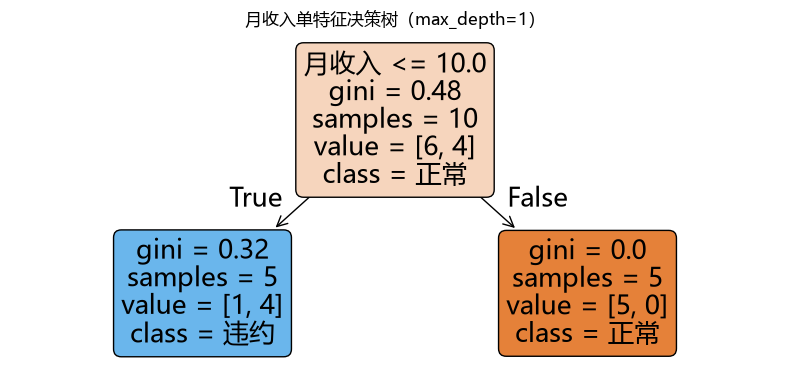

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_tree(
    dt,
    feature_names=["月收入"],
    class_names=["正常", "违约"],
    filled=True,
    rounded=True,
    ax=ax,
)
ax.set_title("月收入单特征决策树（max_depth=1）")
fig.tight_layout()
fig.savefig("images/notes13_fig_tree_income.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.7 小结

- 基尼不纯度衡量节点混杂程度：$Gini=1-\sum p_k^2$，二分类为 $2p(1-p)$；
- 一次分裂用加权基尼评分：$Gini_{split}=\frac{n_L}{n}Gini_L+\frac{n_R}{n}Gini_R$；
- 加权基尼越小，分裂越好；基尼增益 = 父节点基尼 − 分裂后加权基尼；
- 当前节点特征取值全相同，则跳过该特征；
- 停止条件：节点纯净，或没有特征可继续分裂；
- 数值特征在相邻取值的中点生成候选阈值，选择加权基尼最小的阈值；
- sklearn 默认长到纯净，容易过拟合，需要 `max_depth`、`min_samples_leaf` 等参数控制。

In [13]:
# 构建数据
case3 = pd.DataFrame({
    # 特征1：有房产：1=有房产，0=没有房产
    "有房产":   [0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1],
    # 特征2：工作稳定：1=工作稳定，0=工作不稳定
    "工作稳定": [0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0],
    # 特征3：信用记录（文本，有序：良好、一般、较差），后面要转成数字
    "信用记录": ["较差", "较差", "一般", "一般", "一般", "较差", "一般", "良好", "一般", "一般", "良好", "较差", "较差", "良好", "较差", "良好"],
    # 特征4：月收入（单位：千元，是连续数字，不用编码，直接用）
    "月收入":   [12, 7, 20, 13, 18, 8, 10, 3, 9, 15, 17, 19, 4, 5, 16, 14],
    # 标签y：是否违约，1=违约，0=没有违约
    "是否违约": [1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0],
}, index=range(1, 17))

credit_order = {"较差": 2, "一般": 1, "良好": 0}

x3 = case3.drop(columns = "是否违约").assign(信用记录=case3["信用记录"].map(credit_order))
y3 = case3["是否违约"].to_numpy()
print(case3.T)
x3

      1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16
有房产    0   1   1   0   0   0   1   1   1   0   0   0   0   0   0   1
工作稳定   0   0   1   0   1   0   1   1   0   1   1   1   1   1   0   0
信用记录  较差  较差  一般  一般  一般  较差  一般  良好  一般  一般  良好  较差  较差  良好  较差  良好
月收入   12   7  20  13  18   8  10   3   9  15  17  19   4   5  16  14
是否违约   1   1   0   1   0   1   0   0   0   0   0   0   1   0   1   0


,有房产,工作稳定,信用记录,月收入
1,0,0,2,12
2,1,0,2,7
3,1,1,1,20
4,0,0,1,13
5,0,1,1,18
6,0,0,2,8
7,1,1,1,10
8,1,1,0,3
9,1,0,1,9
10,0,1,1,15


In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

tree3 = DecisionTreeClassifier(random_state=0).fit(x3, y3)

print(export_text(tree3, feature_names=list(x3.columns)))

|--- 信用记录 <= 1.50
|   |--- 工作稳定 <= 0.50
|   |   |--- 有房产 <= 0.50
|   |   |   |--- class: 1
|   |   |--- 有房产 >  0.50
|   |   |   |--- class: 0
|   |--- 工作稳定 >  0.50
|   |   |--- class: 0
|--- 信用记录 >  1.50
|   |--- 月收入 <= 17.50
|   |   |--- class: 1
|   |--- 月收入 >  17.50
|   |   |--- class: 0



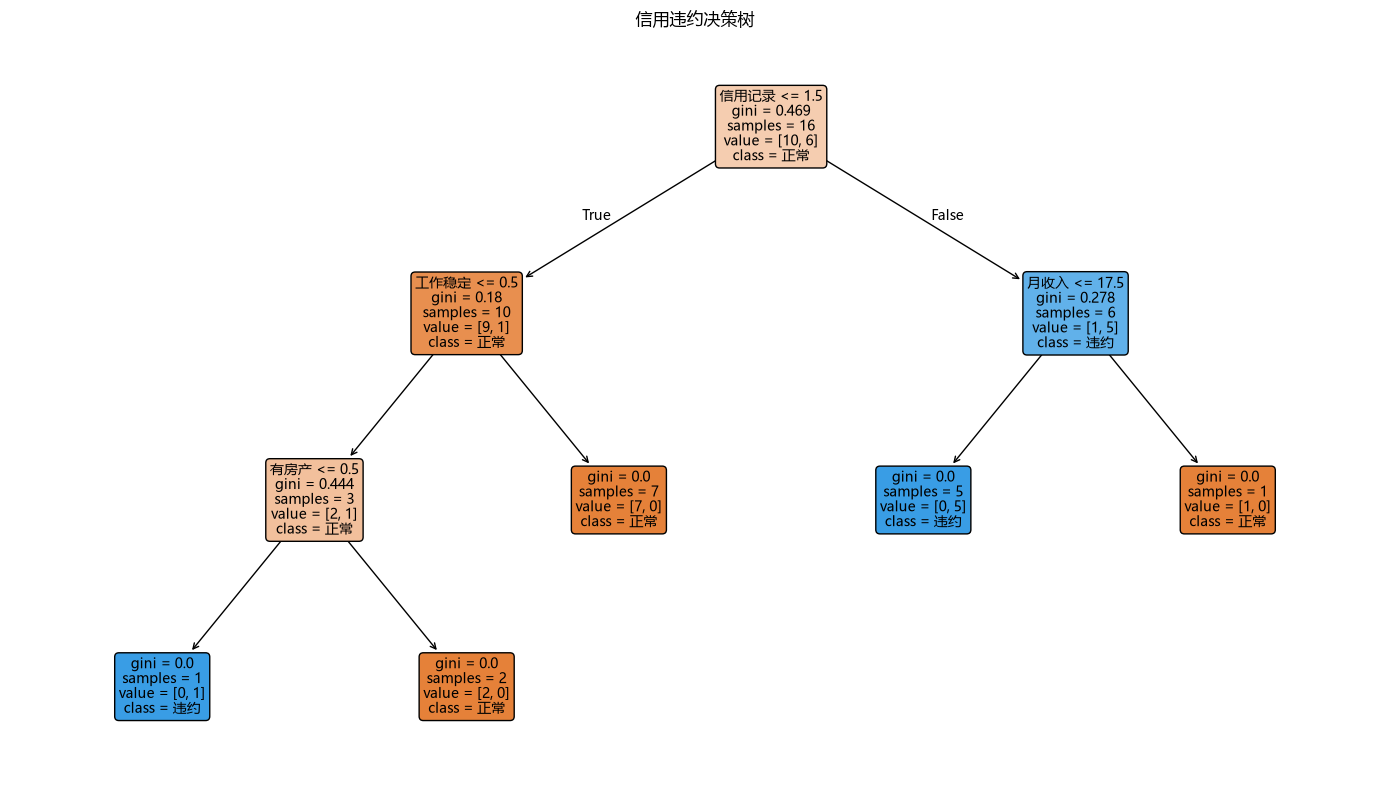

In [15]:
fig, ax = plt.subplots(figsize=(14, 8))
plot_tree(
    tree3,
    feature_names=list(x3.columns),
    class_names=["正常", "违约"],
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax,
)
ax.set_title("信用违约决策树")
fig.tight_layout()
fig.savefig("images/notes13_fig_tree_case3.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
import numpy as np
import pandas as pd

person = pd.DataFrame({"有房产":[0], "工作稳定":[0], "信用记录":[1], "月收入":[11]})

path = tree3.decision_path(person).indices

leaf = tree3.apply(person)[0]

print("经过的节点: ", path, " 到达的叶子: ", leaf)
# tree3.tree_.n_node_samples[leaf]: 取出这片叶子节点里，原来训练时一共有多少个样本
print("叶子里的训练样本: ", tree3.tree_.n_node_samples[leaf], "人")

# predict_proba: 输出[不违约概率, 违约概率], [0,1]就是取违约那一列
# predict: 输出最终预测类别, 1代表违约, 0代表不违约
print("违约概率: ", tree3.predict_proba(person)[0,1], " 预测: ", tree3.predict(person)[0])

经过的节点:  [0 1 2 3]  到达的叶子:  3
叶子里的训练样本:  1 人
违约概率:  1.0  预测:  1


In [17]:
import pandas as pd

# 新数据
# 有房产:[0] → 0=没有房产
# 工作稳定:[0] → 0=工作不稳定
# 信用记录:[1] → 1=一般（之前编码：0良好，1一般，2较差）
# 月收入:[11] → 月收入11千元
person = pd.DataFrame({"有房产": [0], "工作稳定": [0], "信用记录": [1], "月收入": [11]})

# decision_path：获取这个样本在树上走过的所有节点，.indices取出节点编号
path = tree3.decision_path(person).indices
# apply(person)：直接返回这个样本最终落到的【叶子节点编号】，取第0个（就1个申请人）
leaf = tree3.apply(person)[0]

print("经过的节点: ", path, " 到达的叶子: ", leaf)
# tree3.tree_.n_node_samples[leaf]：取出这片叶子节点里，原来训练时一共有多少个样本
print("叶子里的训练样本: ", tree3.tree_.n_node_samples[leaf], "人")

# predict_proba：输出[不违约概率, 违约概率]，[0,1]就是取违约那一列
# predict：输出最终预测类别，1代表违约，0代表不违约
print("违约概率: ", tree3.predict_proba(person)[0,1], " 预测: ", tree3.predict(person)[0])

经过的节点:  [0 1 2 3]  到达的叶子:  3
叶子里的训练样本:  1 人
违约概率:  1.0  预测:  1


In [18]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

X3_onehot = pd.get_dummies(case3.drop(columns="是否违约"), columns=["信用记录"], dtype=int)
X3_onehot

,有房产,工作稳定,月收入,信用记录_一般,信用记录_良好,信用记录_较差
1,0,0,12,0,0,1
2,1,0,7,0,0,1
3,1,1,20,1,0,0
4,0,0,13,1,0,0
5,0,1,18,1,0,0
6,0,0,8,0,0,1
7,1,1,10,1,0,0
8,1,1,3,0,1,0
9,1,0,9,1,0,0
10,0,1,15,1,0,0


In [19]:
tree3b = DecisionTreeClassifier(random_state=0).fit(X3_onehot, y3)
print("独热编码后的列表：", list(X3_onehot.columns))

print(export_text(tree3b, feature_names=list(X3_onehot.columns)))

独热编码后的列表： ['有房产', '工作稳定', '月收入', '信用记录_一般', '信用记录_良好', '信用记录_较差']
|--- 信用记录_较差 <= 0.50
|   |--- 工作稳定 <= 0.50
|   |   |--- 有房产 <= 0.50
|   |   |   |--- class: 1
|   |   |--- 有房产 >  0.50
|   |   |   |--- class: 0
|   |--- 工作稳定 >  0.50
|   |   |--- class: 0
|--- 信用记录_较差 >  0.50
|   |--- 月收入 <= 17.50
|   |   |--- class: 1
|   |--- 月收入 >  17.50
|   |   |--- class: 0



In [20]:
import numpy as np

def entropy(y):
    """
    计算一组 0/1 标签的信息熵。
    二分类信息熵公式：
        Ent = -p * log2(p) - (1-p) * log2(1-p)
    约定 0 * log2(0) = 0。
    """
    p = y.mean()   # y 中 1 的比例，也就是违约比例 p
    # 分别计算“违约比例”和“正常比例”的熵项
    # 如果比例是 0，就按 0 处理，避免 log(0)
    return -sum(q * np.log2(q) for q in [p, 1 - p] if q > 0)

def info_gain(col, y):
    """
    计算某个离散特征 col 的信息增益。
    col：某一列特征，比如“有房产”“工作稳定”“信用记录”
    y：标签，1=违约，0=正常
    返回：信息增益 gain，固有值 iv
    """
    H = entropy(y)              # 拆分前整组数据的熵
    groups = []                  # 准备保存每个分组的比例和熵

    # 遍历这个特征的每一个不同取值
    # 比如“信用记录”有三个值，就分成三个分支
    for v in np.unique(col):
        mask = col == v         # 选出特征等于 v 的样本
        w = mask.mean()         # 这个分支的人数占比
        e = entropy(y[mask])    # 这个分支内部的熵
        groups.append((w, e))   # 保存：比例、熵

    # 加权熵：每个分支的熵按人数比例加权相加，用于计算信息增益
    weighted_entropy = sum(w * e for w, e in groups)

    # 信息增益 = 拆分前的熵 - 拆分后的加权熵
    gain = H - weighted_entropy

    # 固有值 IV（分裂信息）：每个分支人数占比的熵，用于计算增益率
    iv = -sum(w * np.log2(w) for w, _ in groups if w > 0)

    return H, gain, iv



# 打印根节点的熵，也就是还没有拆分前的混乱程度
print("根节点的熵：", round(entropy(y3), 4))

# 逐个尝试三个特征，看哪个特征拆分效果最好
for c in ["有房产", "工作稳定", "信用记录"]:
    g = info_gain(x3[c].to_numpy(), y3)

    # g[1]：信息增益 gain
    # g[2]：固有值 iv
    # 增益率 = 信息增益 / 固有值
    print(f"{c} 信息增益 {g[1]:.4f} IV {g[2]:.4f} 增益率 {g[1]/g[2]:.4f}")

根节点的熵： 0.9544
有房产 信息增益 0.0857 IV 0.9544 增益率 0.0898
工作稳定 信息增益 0.2937 IV 0.9887 增益率 0.2971
信用记录 信息增益 0.4669 IV 1.5613 增益率 0.2991


In [21]:
# 把“编号”也当成特征，看信息增益为什么会上当，增益率又怎样纠正
# 生成1~16的编号，16个样本，每个编号唯一
ids = np.arange(1,17)
# 计算编号这个特征的信息增益g、固有值iv
h, g, iv = info_gain(ids, y3)
print(h,g,iv)
print(f"编号：信息增益 {g:.4f}(等于根节点的熵) IV {iv:.4f} 增益率 {g / iv:.4f}")
# 批量计算多个特征：有房产、工作稳定、信用记录、月收入、编号，保存(gain,iv)
gains = {c: info_gain(x3[c].to_numpy(),y3)[1:] for c in ["有房产","工作稳定","信用记录"]}
gains["月收入（≤ 16.5）"] = info_gain((x3["月收入"] <= 16.5).to_numpy().astype(int), 
y3)[1:]
gains["编号"] = (g, iv)
# C4.5第一步：算出所有特征信息增益的平均值
avg = np.mean([v[0] for v in gains.values()])
print("五个特征信息增益的平均值: ", round(avg, 4))
# C4.5第二步：过滤，只留下增益大于等于平均值的特征，计算它们的增益率
ok = {k: v[0] / v[1] for k, v in gains.items() if v[0] >= avg}
print("高于平均的特征及其增益率: ", {k: round(v, 4) for k, v in ok.items()})
# C4.5第三步：在筛选后的里面，选出增益率最大的特征
print("C4.5 选: ", max(ok, key=ok.get))

0.954434002924965 0.954434002924965 4.0
编号：信息增益 0.9544(等于根节点的熵) IV 4.0000 增益率 0.2386
五个特征信息增益的平均值:  0.401
高于平均的特征及其增益率:  {'信用记录': np.float64(0.2991), '编号': np.float64(0.2386)}
C4.5 选:  信用记录


In [22]:
# 导入库
import pandas as pd  # 缺失导入，读取CSV需要
import numpy as np   # 缺失导入，计算平均值等需要
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# ==========================================
# 第一部分：在自定义数据集(X3, y3)上对比 gini 和 entropy
# ==========================================
# 循环分别用两种分裂准则：gini(基尼不纯度)、entropy(信息熵，信息增益)
for crit in ['gini', 'entropy']:
    # 新建决策树，指定分裂准则crit，固定随机种子保证结果可复现，在X3, y3上训练
    tr = DecisionTreeClassifier(criterion=crit, random_state=0).fit(x3, y3)
    
    # tr.tree_.feature[0] 代表【根节点】分裂用的特征下标；X3.columns[下标]拿到特征名字
    # get_n_leaves()：统计这棵树一共有多少叶子节点（叶子越多树越复杂）
    print(f"{crit:<8} 根节点 问的是 {x3.columns[tr.tree_.feature[0]]}, 叶子 {tr.get_n_leaves()} 片")


# ==========================================
# 第二部分：在真实的信贷数据集上做交叉验证对比
# ==========================================
# 读取信贷数据.csv数据集，做5折分层交叉验证对比
df = pd.read_csv('../data/信贷数据.csv')

# 挑选只用来建模的数值型特征列表
num = ["年龄", "月收入", "负债收入比", "额度使用率", "逾期次数", "工作年限"]

# 目标值
Xn, yc = df[num], df['是否违约'].to_numpy()

# 构造分层5折交叉验证器（保证每折中正负样本比例一致）
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# 再次循环对比gini、entropy
for crit in ['gini', 'entropy']:
    # 模型：决策树，指定准则crit，限制最大深度max_depth=4防止过拟合，固定随机种子
    dtc = DecisionTreeClassifier(criterion=crit, max_depth=4, random_state=0)
    
    # cv=cv：使用上面定义好的分层5折；scoring="roc_auc"：评估指标用AUC（信贷二分类非常常用）
    auc = cross_val_score(dtc, Xn, yc, cv=cv, scoring='roc_auc')
    
    # auc.mean()：5折AUC求平均值，用来衡量模型整体效果，保留4位小数打印
    print(f"{crit:<8} 信贷数据：5折AUC {auc.mean():.4f}")

gini     根节点 问的是 信用记录, 叶子 5 片
entropy  根节点 问的是 信用记录, 叶子 5 片
gini     信贷数据：5折AUC 0.6883
entropy  信贷数据：5折AUC 0.6827


In [29]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

def make_2d (seed = 273, n = 800):
    r = np.random.default_rng(seed)
    inc = np.round(r.uniform(3, 25, size=n), 1)
    debt = np.round(np.clip(r.beta(2.2, 3, n), 0.01, 0.99), 3)
    risky = (debt > 0.22 + 0.022 * inc) | ((inc < 6) & (debt > 0.2))
    y = (risky ^ (r.random(n) < 0.12)).astype(int)
    X = np.c_[inc, debt]
    return X[:200], y[:200], X[200:], y[200:]

Xtr2, ytr2, Xva2, yva2 = make_2d()
rows = []

for d in [1 ,2, 3, 4, 5, 6, 7, 8, 9, 10, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr2, ytr2)
    rows.append([str(d), m.score(Xtr2, ytr2), round(m.score(Xte2, yte2), 3), round(m.score(Xva2, yva2), 3)])

df = pd.DataFrame(rows, columns=["最大深度", "叶子数量", "训练集准确率", "验证集准确率"])
df

,最大深度,叶子数量,训练集准确率,验证集准确率
0,1,0.725,0.708,0.708
1,2,0.785,0.790,0.790
2,3,0.825,0.812,0.812
3,4,0.870,0.778,0.778
4,5,0.895,0.755,0.755
5,6,0.920,0.743,0.743
6,7,0.935,0.730,0.730
7,8,0.960,0.733,0.733
8,9,0.975,0.718,0.718
9,10,0.990,0.712,0.712


In [38]:
grid = {
    "min_samples_leaf": [1, 5, 12, 30], 
    "min_samples_split": [2, 10, 40, 100],
    "min_impurity_decrease": [0, 0.004, 0.02, 0.08], 
    "max_leaf_nodes": [4, 8, 16, None]}

# 循环遍历每一个刹车参数 (注：原文注释可能为“超参数”的笔误)
for p, vals in grid.items():
    # 记录每一个刹车参数 结果
    res = []
    for v in vals:
        # 创建决策树实例，如果v是None，就不传这个参数，使用默认；否则设置参数p=v
        m = DecisionTreeClassifier(random_state=0, **({p:v} if v is not None else {})).fit(Xtr2, ytr2)
        # 记录：参数取值、叶子数量、验证集准确率
        res.append(f"{v}:叶 {m.get_n_leaves()} 验 {m.score(Xva2, yva2):.3f}")
    print(f"{p:<22}", " ".join(res))

min_samples_leaf       1:叶 53 验 0.707 5:叶 27 验 0.785 12:叶 15 验 0.787 30:叶 6 验 0.762
min_samples_split      2:叶 53 验 0.707 10:叶 31 验 0.757 40:叶 8 验 0.787 100:叶 4 验 0.737
min_impurity_decrease  0:叶 53 验 0.707 0.004:叶 21 验 0.783 0.02:叶 5 验 0.812 0.08:叶 2 验 0.708
max_leaf_nodes         4:叶 4 验 0.790 8:叶 8 验 0.802 16:叶 16 验 0.773 None:叶 53 验 0.707


In [39]:
import numpy as np

# 定义计算基尼不纯度的函数，接收标签列表y（只有0和1）
def gini(y):
    """
    y 是 0/1 标签；
    基尼不纯度公式：Gini = 1 − (违约比例)² − (正常比例)²
    直观含义：随机抽两个样本，类别不一样的概率
    """
    # 将传入的列表转为numpy数组，方便调用mean()求平均值
    y = np.array(y)
    # 边界判断：如果这一组样本为空，没有数据，基尼直接返回0
    if len(y) == 0:
        return 0.0
    # 数组里只有0和1，求平均值，结果就是标签1（违约）在本组里的占比p  
    p = y.mean()
    # 代入基尼公式计算，返回基尼不纯度
    return 1 - p**2 - (1-p)**2

# 目的：对根节点，按每个特征分成两组，算两组的基尼和加权基尼，挑最小的
def weighted_gini(y, mask):
    """
    mask 为 True 的去右边、False 的去左边；
    返回（左边基尼，右边基尼，加权基尼）
    """
    # mask 是一串 True / False：True 的人去右边，False 的人去左边（~ 是“取反”）
    left, right = y[~mask], y[mask]
    gl, gr = gini(left), gini(right)
    # 加权平均：人多的那一组，说话的分量重
    return gl, gr, (len(left)*gl + len(right)*gr) / len(y)

# 目的：在二维数据的根节点上试遍所有候选划分，验证“加权基尼 ≤ 划分前的基尼”
g0, worse, total = gini(ytr2), 0, 0
for j in range(2):                                          
    # 两个特征
    vals = np.unique(Xtr2[:, j])
    # 这个特征的每一条候选分界线
    for t_ in (vals[:-1] + vals[1:]) / 2:                   
        # 每个候选阈值
        wg = weighted_gini(ytr2, Xtr2[:, j] > t_)[2]
        # total 数一共试了多少种分法；worse 数其中有多少种“分完反而更混”
        total += 1; worse += wg > g0 + 1e-12
        
print(f"划分前基尼 {g0:.4f}；试了 {total} 个划分，加权基尼比划分前大的有 {worse} 个")

划分前基尼 0.4888；试了 305 个划分，加权基尼比划分前大的有 0 个


In [40]:
import numpy as np
import pandas as pd

# Xv、yv：独立的8条验证数据
Xv = pd.DataFrame({
    "有房产": [1, 0, 0, 1, 0, 0, 1, 0], 
    "工作稳定": [1, 1, 0, 0, 1, 0, 1, 1],
    "信用记录": [0, 1, 1, 0, 0, 2, 2, 2], 
    "月收入": [12, 9, 7, 15, 6, 10, 20, 14]
})
yv = np.array([0, 0, 1, 0, 1, 1, 1, 0])

T = tree3.tree_ # 取出之前训练好那棵决策树的内部结构

def predict_pruned(X, as_leaf):
    """
    模拟剪枝预测
    as_leaf：放我们强制当成叶子的节点编号，走到这些节点就不再往下分裂
    """
    out = []
    for row in X.to_numpy():
        k = 0 # 从根节点0开始走
        # 循环：当前节点还有子节点，并且不在停止名单里，就继续往下走
        while T.children_left[k] != -1 and k not in as_leaf:
            # 根据阈值往左子树、右子树走
            k = T.children_left[k] if row[T.feature[k]] <= T.threshold[k] else T.children_right[k]
        # 停下来：用训练集里面多数类别作为预测结果
        out.append(int(np.argmax(T.value[k][0])))
    return np.array(out)

# inner：找出所有可以分裂的内部节点（不是叶子的节点）
inner = [k for k in range(T.node_count) if T.children_left[k] != -1]

# 循环测试4种不同的停止方案，分别统计验证集答对数量
for name, leaf_set in [
    ("一刀不切", set(inner)), 
    ("只切根节点", {1, 2, 6}), 
    ("再切节点②", {2, 6}), 
    ("根和节点⑦", {1, 2})
]:
    print(f"{name:<6} 验证集答对 {(predict_pruned(Xv, leaf_set) == yv).sum()} / 8")

一刀不切   验证集答对 4 / 8
只切根节点  验证集答对 5 / 8
再切节点②  验证集答对 5 / 8
根和节点⑦  验证集答对 4 / 8


In [42]:
import pandas as pd
import numpy as np

# 准备数据集
Xv = pd.DataFrame({
    "有房产": [1, 0, 0, 1, 0, 0, 1, 0],
    "工作稳定": [1, 1, 0, 0, 1, 0, 1, 1],
    "信用记录": [0, 1, 1, 0, 0, 2, 2, 2],
    "月收入": [12, 9, 7, 15, 6, 10, 20, 14]
})
yv = np.array([0, 0, 1, 0, 1, 1, 1, 0])

T = tree3.tree_

# 原来的预测函数
def predict_pruned(X, as_leaf):
    """沿着 tree3 往下走；遇到 as_leaf 里的节点就停下，用它的训练集多数类当预测"""
    out = []
    for row in X.to_numpy():
        k = 0
        # 只要当前节点还有孩子、又不在“当叶子”的名单里，就继续往下走
        while T.children_left[k] != -1 and k not in as_leaf:
            k = T.children_left[k] if row[T.feature[k]] <= T.threshold[k] else T.children_right[k]
        # 停下来以后：这个节点里训练集哪一类多，就预测哪一类
        out.append(int(np.argmax(T.value[k][0])))
    return np.array(out)

# pruned：记录我们决定剪掉的节点编号
pruned = set()

# 循环顺序 [2, 1, 6, 0]：后序遍历，先处理深层子节点
for k in [2, 1, 6, 0]:
    # reach：找出验证集里，路径会走到节点k的样本下标
    reach = [i for i in range(len(yv)) if k in tree3.decision_path(Xv.iloc[[i]]).indices]
    
    # 如果没有任何验证集样本经过这个节点，就没必要试了，直接跳过
    if not reach:
        continue
        
    # keep：保留这棵子树的时候，这些样本预测错多少个
    keep = (predict_pruned(Xv.iloc[reach], pruned) != yv[reach]).sum()
    
    # cut：把节点k直接改成叶子、把子树全部剪掉，这些样本会错多少个 
    # 【重要修复】原图此处括号严重错位，且误将 != 写在了括号里
    cut = (predict_pruned(Xv.iloc[reach], pruned | {k}) != yv[reach]).sum()
    
    # 判断：剪掉之后错误不增加，就剪，加入剪枝集合
    if cut <= keep:
        pruned.add(k)
        
    print(f"节点（sklearn 编号）{k}: 验证集 {len(reach)} 人，保留子树错 {keep}, 换成叶子错 {cut} -> {'剪' if cut <= keep else '保留'}")

print("剪完后验证集答对：", (predict_pruned(Xv, pruned) == yv).sum(), "/8")

节点（sklearn 编号）2: 验证集 2 人，保留子树错 0, 换成叶子错 1 -> 保留
节点（sklearn 编号）1: 验证集 5 人，保留子树错 1, 换成叶子错 2 -> 保留
节点（sklearn 编号）6: 验证集 3 人，保留子树错 2, 换成叶子错 1 -> 剪
节点（sklearn 编号）0: 验证集 8 人，保留子树错 2, 换成叶子错 4 -> 保留
剪完后验证集答对： 6 /8


In [47]:
from sklearn.tree import DecisionTreeClassifier

path = tree3.cost_complexity_pruning_path(x3, y3)

for a in path.ccp_alphas:
    m = DecisionTreeClassifier(
        random_state=0,
        ccp_alpha=a,
    ).fit(x3, y3)
    correct = (m.predict(Xv) == yv).sum()
    print(
        f"ccp_alpha = {a:.4f}: "
        f"叶子 {m.get_n_leaves()}, "
        f"验证集答对 {correct}, "
        f"准确率：{correct / len(yv):.3f}"
    )

ccp_alpha = 0.0000: 叶子 5, 验证集答对 5, 准确率：0.625
ccp_alpha = 0.0563: 叶子 3, 验证集答对 4, 准确率：0.500
ccp_alpha = 0.1042: 叶子 2, 验证集答对 5, 准确率：0.625
ccp_alpha = 0.2521: 叶子 1, 验证集答对 4, 准确率：0.500
